# Model Fitness: Customer Churn Prediction and Segmentation

**Summary (EN):** Data-driven retention analysis for a gym chain (4,000 customers, 13 features). The project covers exploratory data analysis, churn prediction with logistic regression and random forest (accuracy 0.92, precision 0.85, recall 0.83 for logistic regression), customer segmentation with hierarchical clustering and K-means (5 clusters, churn from 3% to 51%), and business recommendations to reduce churn.

**Tools:** Python, pandas, NumPy, scikit-learn, SciPy, Matplotlib, Seaborn.

> The analysis below is written in Portuguese. *Note: the dataset comes from the TripleTen Data Analyst bootcamp and is not included in this repository.*


# Projeto Sprint 13: Rotatividade de clientes da Model Fitness

## Introdução

A rede de academias Model Fitness quer desenvolver uma estratégia de retenção de clientes baseada em dados. Neste projeto, vamos:

1. Estudar os dados e fazer a análise exploratória (AED).
2. Construir um modelo para prever a rotatividade (*churn*) dos clientes.
3. Agrupar os clientes e descrever os perfis mais marcantes.
4. Chegar a conclusões e recomendações para reduzir a rotatividade.

---

## Passo 1. Baixar os dados

Nesta etapa vamos importar as bibliotecas, ler o arquivo `gym_churn_us.csv` e ver as informações gerais do conjunto de dados: tamanho, primeiras linhas, tipos de dados e valores ausentes.

In [1]:
# importar as bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans

# ler os dados
# ler os dados (caminho da plataforma; se rodar localmente, use o arquivo na mesma pasta)
try:
    gym = pd.read_csv('/datasets/gym_churn_us.csv')
except FileNotFoundError:
    gym = pd.read_csv('gym_churn_us.csv')

# tamanho do conjunto de dados
print('Tamanho do conjunto de dados:', gym.shape)
print()

# primeiras linhas
display(gym.head())
print()

# informações gerais: tipos de dados e valores não nulos
gym.info()

Tamanho do conjunto de dados: (4000, 14)



,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   floa

### Avaliação do Passo 1

O conjunto de dados `gym_churn_us.csv` tem **4.000 observações (clientes) e 14 colunas**: 13 características e a variável objetivo `Churn`.

- **Valores ausentes:** todas as colunas têm 4.000 valores não nulos, então não há valores ausentes e não é preciso tratamento.
- **Tipos de dados:** 10 colunas são `int64` e 4 são `float64`, e todas são numéricas. As colunas binárias (`gender`, `Near_Location`, `Partner`, `Promo_friends`, `Phone`, `Group_visits` e `Churn`) já estão codificadas como 0 e 1, então não é preciso converter nada.
- **Colunas contínuas:** `Avg_additional_charges_total`, `Month_to_end_contract`, `Avg_class_frequency_total` e `Avg_class_frequency_current_month` são `float64`.
- **Nome das colunas:** a coluna de idade se chama `Age` (com maiúscula), e vamos usá-la com esse nome nos próximos passos.

Os dados estão prontos para a análise exploratória.

## Passo 2. Análise exploratória dos dados (AED)

Nesta etapa vamos:

1. Verificar se há valores ausentes e estudar a média e o desvio padrão de cada característica com `describe()`.
2. Comparar os valores médios das características entre os clientes que **saíram** (`Churn = 1`) e os que **ficaram** (`Churn = 0`), usando `groupby()`.
3. Construir histogramas das características para os dois grupos.
4. Construir a matriz de correlação.

Valores ausentes por coluna:
gender                               0
Near_Location                        0
Partner                              0
Promo_friends                        0
Phone                                0
Contract_period                      0
Group_visits                         0
Age                                  0
Avg_additional_charges_total         0
Month_to_end_contract                0
Lifetime                             0
Avg_class_frequency_total            0
Avg_class_frequency_current_month    0
Churn                                0
dtype: int64



,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,0.510250,0.845250,0.486750,0.308500,0.903500,4.681250,0.412250,29.184250,146.943728,4.322750,3.724750,1.879020,1.767052,0.265250
std,0.499957,0.361711,0.499887,0.461932,0.295313,4.549706,0.492301,3.258367,96.355602,4.191297,3.749267,0.972245,1.052906,0.441521
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,18.000000,0.148205,1.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,27.000000,68.868830,1.000000,1.000000,1.180875,0.963003,0.000000
50%,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,29.000000,136.220159,1.000000,3.000000,1.832768,1.719574,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,6.000000,1.000000,31.000000,210.949625,6.000000,5.000000,2.536078,2.510336,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,12.000000,1.000000,41.000000,552.590740,12.000000,31.000000,6.023668,6.146783,1.000000


Valores médios por grupo (Churn):


Churn,0,1
gender,0.51,0.51
Near_Location,0.87,0.77
Partner,0.53,0.36
Promo_friends,0.35,0.18
Phone,0.90,0.90
Contract_period,5.75,1.73
Group_visits,0.46,0.27
Age,29.98,26.99
Avg_additional_charges_total,158.45,115.08
Month_to_end_contract,5.28,1.66


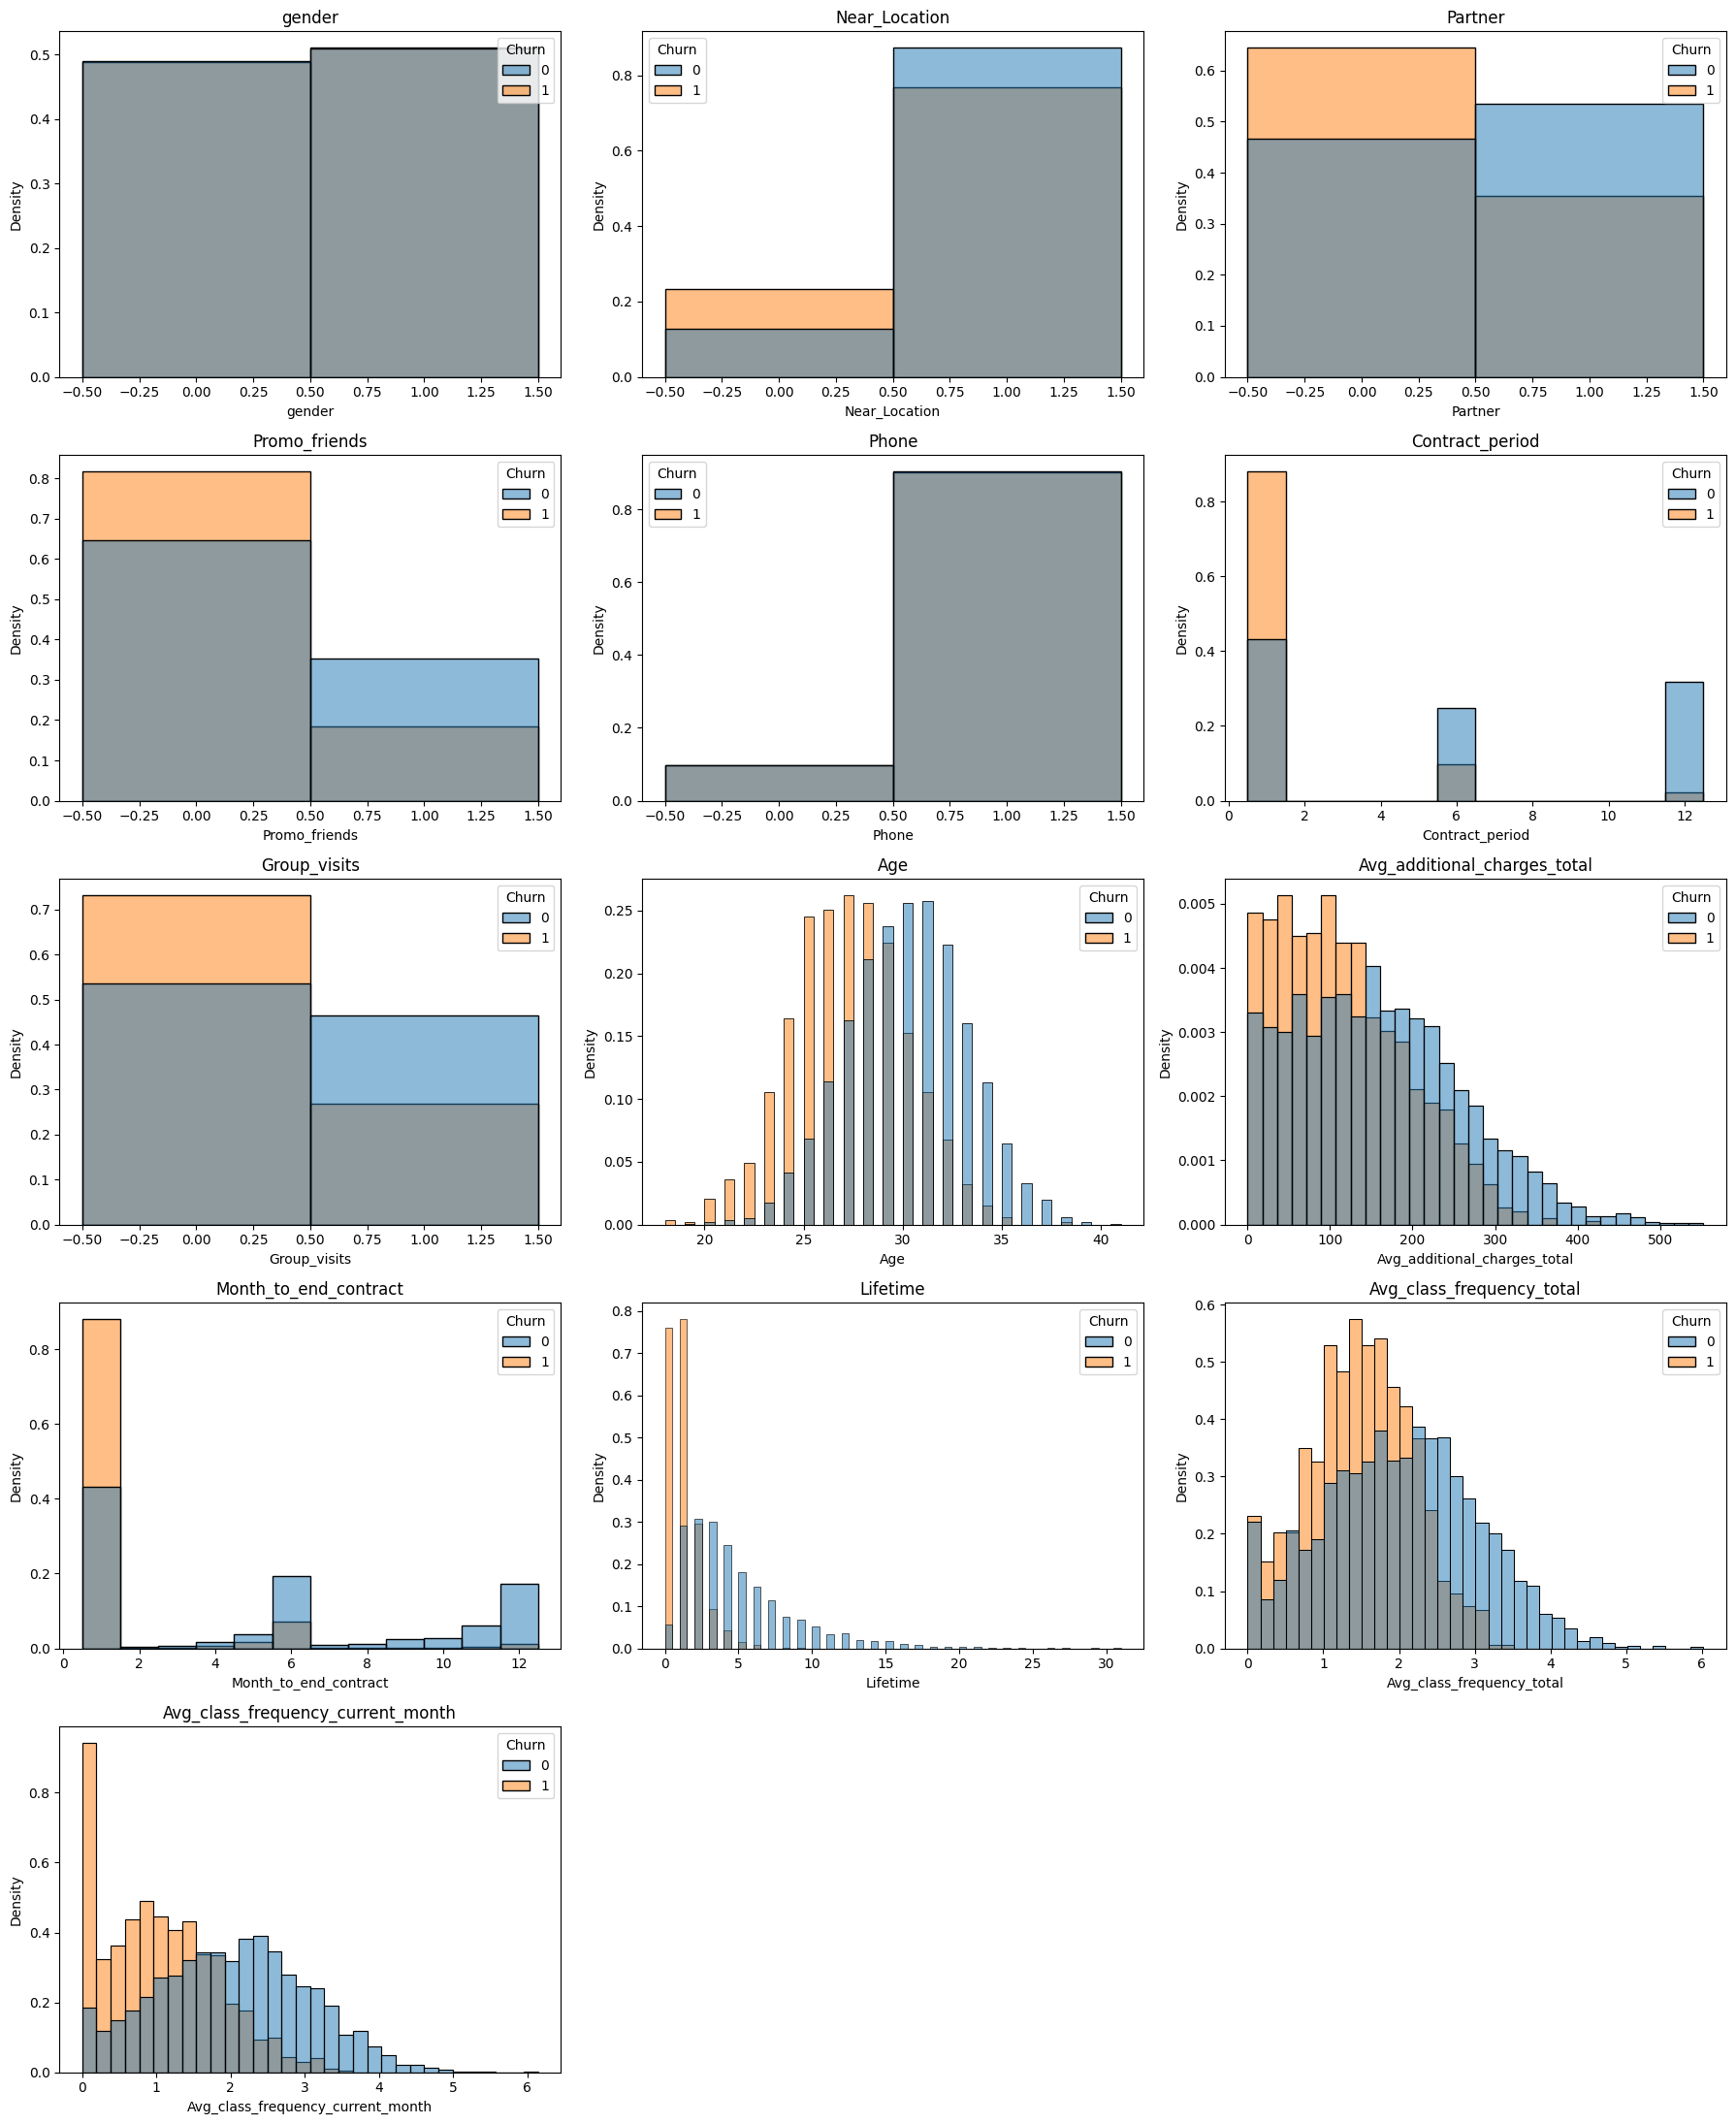

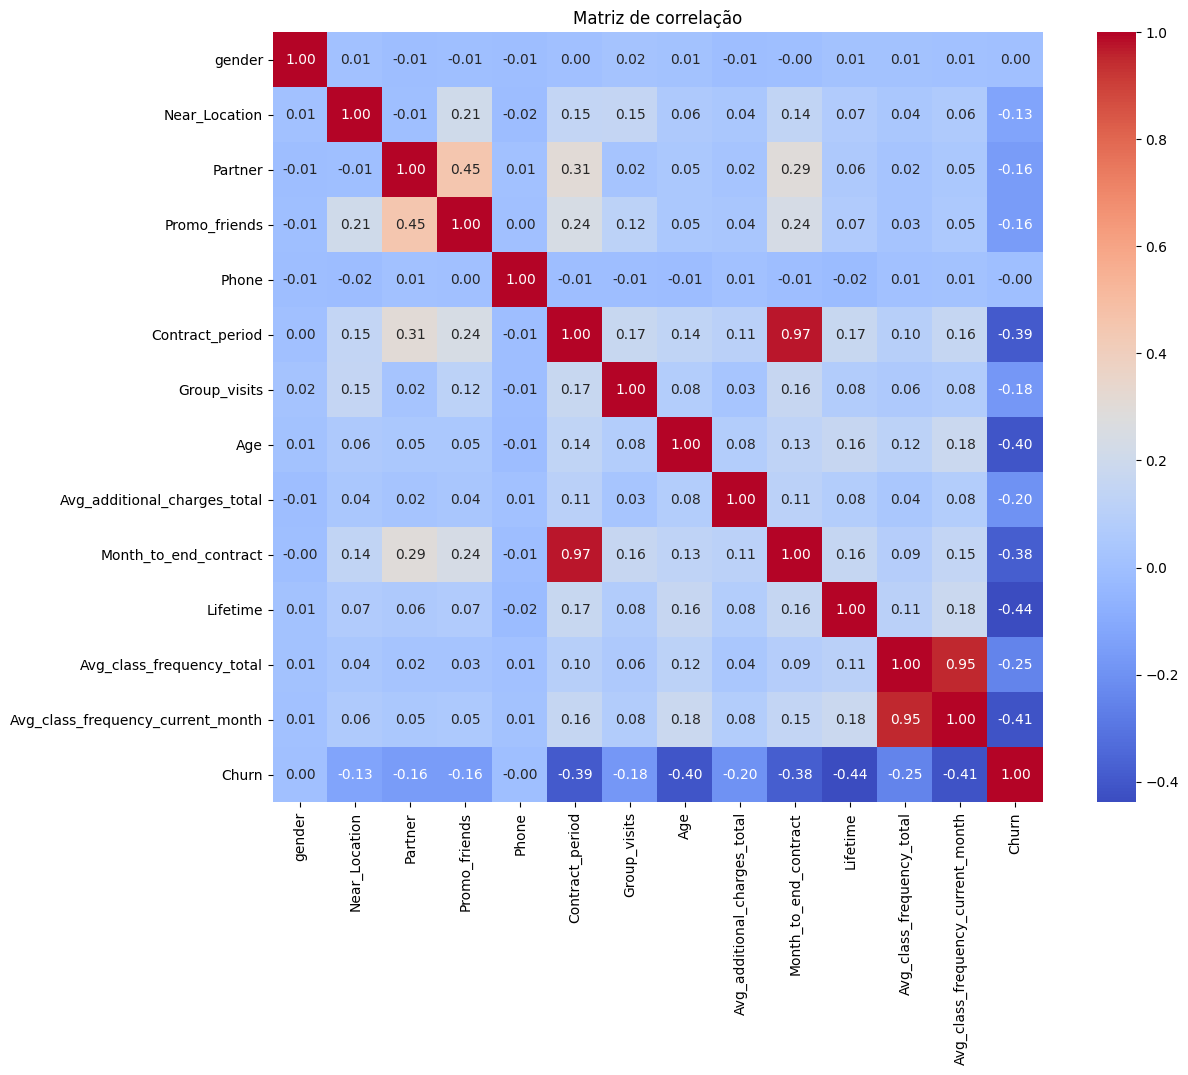

In [2]:
# 1. valores ausentes
print('Valores ausentes por coluna:')
print(gym.isna().sum())
print()

# média, desvio padrão e demais estatísticas
display(gym.describe())

# 2. valores médios das características para quem ficou (0) e quem saiu (1)
print('Valores médios por grupo (Churn):')
display(gym.groupby('Churn').mean().T.round(2))

# 3. histogramas das características para os dois grupos
features = [col for col in gym.columns if col != 'Churn']

fig, axes = plt.subplots(5, 3, figsize=(18, 22))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sns.histplot(data=gym, x=col, hue='Churn', stat='density', common_norm=False,
                 discrete=(gym[col].nunique() <= 12), ax=ax)
    ax.set_title(col)

# remover os gráficos vazios que sobrarem
for ax in axes[len(features):]:
    ax.remove()

plt.tight_layout()
plt.show()

# 4. matriz de correlação
plt.figure(figsize=(14, 10))
sns.heatmap(gym.corr(), annot=True, fmt='.2f', square=True, cmap='coolwarm')
plt.title('Matriz de correlação')
plt.show()

### Avaliação do Passo 2

**Valores ausentes e estatísticas descritivas**

- Não há valores ausentes em nenhuma coluna.
- As características binárias têm médias que mostram o perfil geral da base: 51% dos clientes são de um dos gêneros, 85% moram ou trabalham perto da academia (`Near_Location`), 49% são de empresas parceiras (`Partner`), 31% vieram por indicação de amigos (`Promo_friends`), 90% deixaram o telefone (`Phone`) e 41% participam de aulas em grupo (`Group_visits`).
- A idade média é de 29 anos (desvio padrão de 3,3), variando de 18 a 41.
- O período médio de contrato é de 4,7 meses, mas a mediana é de 1 mês, o que indica que a maioria dos clientes tem contrato de 1 mês, enquanto alguns têm contratos longos (até 12 meses).
- O gasto médio com serviços adicionais é de 146,94, com grande variação (desvio padrão de 96,36 e máximo de 552,59).
- O tempo médio de permanência (`Lifetime`) é de 3,7 meses, com máximo de 31.

**Médias por grupo (`Churn = 0` ficaram e `Churn = 1` saíram)**

| Característica | Ficaram | Saíram |
|---|---|---|
| `Contract_period` | 5,75 | 1,73 |
| `Month_to_end_contract` | 5,28 | 1,66 |
| `Lifetime` | 4,71 | 0,99 |
| `Avg_class_frequency_current_month` | 2,03 | 1,04 |
| `Avg_class_frequency_total` | 2,02 | 1,47 |
| `Avg_additional_charges_total` | 158,45 | 115,08 |
| `Age` | 29,98 | 26,99 |
| `Partner` | 0,53 | 0,36 |
| `Promo_friends` | 0,35 | 0,18 |
| `Group_visits` | 0,46 | 0,27 |
| `Near_Location` | 0,87 | 0,77 |
| `gender` | 0,51 | 0,51 |
| `Phone` | 0,90 | 0,90 |

Quem saiu tem, em média, contratos bem mais curtos, menos tempo de casa, frequência atual mais baixa (cerca de metade), gasta menos em serviços adicionais e é um pouco mais jovem. Também participa menos de aulas em grupo, é menos frequentemente de empresa parceira ou vindo de indicação, e mora um pouco mais longe. `gender` e `Phone` têm médias iguais nos dois grupos, então parecem não influenciar a rotatividade.

**Histogramas**

- Os clientes que saíram se concentram em `Contract_period = 1`, `Month_to_end_contract` próximo de 1 e `Lifetime` entre 0 e 2 meses, ou seja, saem logo no início do relacionamento.
- Na frequência do mês atual (`Avg_class_frequency_current_month`), há um pico forte perto de 0 para quem saiu, e quem ficou se distribui em torno de 2 visitas por semana.
- A distribuição de idade dos que saíram está deslocada para valores menores (em torno de 25 a 28 anos), e a dos que ficaram, para valores maiores (em torno de 29 a 33).
- O gasto adicional dos que ficaram tem uma cauda mais longa para valores altos.
- `gender` e `Phone` têm distribuições praticamente idênticas nos dois grupos.

**Matriz de correlação**

- Correlações mais fortes com `Churn` (todas negativas): `Lifetime` (-0,44), `Avg_class_frequency_current_month` (-0,41), `Age` (-0,40), `Contract_period` (-0,39) e `Month_to_end_contract` (-0,38). Isso significa que quanto maior o valor dessas características, menor a chance de sair.
- Correlações moderadas: `Avg_class_frequency_total` (-0,25) e `Avg_additional_charges_total` (-0,20). As demais ficam entre -0,13 e -0,18, e `gender` e `Phone` têm correlação praticamente nula com `Churn` (0,00).
- **Há características fortemente correlacionadas entre si (multicolinearidade):** `Contract_period` e `Month_to_end_contract` (0,97) e `Avg_class_frequency_total` e `Avg_class_frequency_current_month` (0,95). Elas carregam quase a mesma informação, o que pode atrapalhar modelos lineares como a regressão logística. Também há uma correlação moderada entre `Partner` e `Promo_friends` (0,45).

## Passo 3. Construir um modelo para prever a rotatividade de clientes

Vamos construir um modelo de classificação binária em que a variável objetivo é `Churn` (se o cliente saiu no mês seguinte).

1. Separar as características (`X`) da variável objetivo (`y`) e dividir os dados em conjuntos de treino e validação com `train_test_split()`.
2. Padronizar as características (o escalonador é treinado só com o conjunto de treino).
3. Treinar dois modelos: **regressão logística** e **floresta aleatória**.
4. Comparar os modelos com **acurácia**, **precisão** e **sensibilidade** nos dados de validação.

In [3]:
# separar características (X) e variável objetivo (y)
X = gym.drop('Churn', axis=1)
y = gym['Churn']

# dividir em treino e validação (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# padronizar as características (escalonador treinado só no treino)
scaler = StandardScaler()
X_train_st = scaler.fit_transform(X_train)
X_test_st = scaler.transform(X_test)

# função que treina o modelo e imprime as métricas
def print_metrics(model, X_tr, y_tr, X_te, y_te, title):
    model.fit(X_tr, y_tr)
    predictions = model.predict(X_te)
    print(title)
    print('\tAcurácia: {:.2f}'.format(accuracy_score(y_te, predictions)))
    print('\tPrecisão: {:.2f}'.format(precision_score(y_te, predictions)))
    print('\tSensibilidade: {:.2f}'.format(recall_score(y_te, predictions)))
    print()

# regressão logística (dados padronizados)
lr_model = LogisticRegression(random_state=0)
print_metrics(lr_model, X_train_st, y_train, X_test_st, y_test, 'Métricas da regressão logística:')

# floresta aleatória
rf_model = RandomForestClassifier(n_estimators=100, random_state=0)
print_metrics(rf_model, X_train_st, y_train, X_test_st, y_test, 'Métricas da floresta aleatória:')

Métricas da regressão logística:
	Acurácia: 0.92
	Precisão: 0.85
	Sensibilidade: 0.83

Métricas da floresta aleatória:
	Acurácia: 0.92
	Precisão: 0.84
	Sensibilidade: 0.81



### Avaliação do Passo 3

Treinamos dois modelos de classificação binária, com divisão 80% / 20% e `random_state=0`. Resultados nos dados de validação:

| Modelo | Acurácia | Precisão | Sensibilidade |
|---|---|---|---|
| Regressão logística | 0,92 | 0,85 | 0,83 |
| Floresta aleatória | 0,92 | 0,84 | 0,81 |

**Como interpretar as métricas neste caso:**

- **Acurácia (0,92):** os dois modelos acertam a situação (saiu ou ficou) de cerca de 92% dos clientes da validação.
- **Precisão (0,85 e 0,84):** quando o modelo prevê que um cliente vai sair, ele acerta cerca de 85% das vezes. Ou seja, poucas ações de retenção seriam gastas com clientes que não iam sair.
- **Sensibilidade (0,83 e 0,81):** dos clientes que de fato saíram, os modelos identificam cerca de 81% a 83%. Os demais saem sem serem detectados.

**Qual modelo rendeu melhores resultados?**

A **regressão logística** teve resultados ligeiramente melhores: mesma acurácia, mas precisão e sensibilidade um pouco mais altas (0,85 contra 0,84 e 0,83 contra 0,81). A diferença, porém, é pequena, de 1 a 2 pontos percentuais, e dentro do que pode mudar com outra divisão dos dados. Por isso, podemos dizer que os dois modelos têm desempenho equivalente.

Como o objetivo é **identificar quem vai sair para agir antes**, a **sensibilidade** é a métrica mais importante, e a regressão logística também tem a vantagem aqui. Ela é ainda um modelo mais simples e fácil de interpretar, o que ajuda a entender quais fatores influenciam a rotatividade (próximo passo da análise).

## Passo 4. Criar agrupamentos de clientes

Nesta etapa vamos agrupar os clientes **sem usar a coluna `Churn`**, para ver se surgem grupos naturais e se eles diferem na taxa de rotatividade.

1. Padronizar os dados (sem `Churn`).
2. Construir a matriz de distâncias com `linkage()` e o dendrograma, para estimar quantos agrupamentos existem.
3. Treinar o modelo **K-means com 5 agrupamentos** e prever o agrupamento de cada cliente.
4. Ver os valores médios das características por agrupamento.
5. Ver as distribuições das características por agrupamento.
6. Calcular a taxa de rotatividade de cada agrupamento.

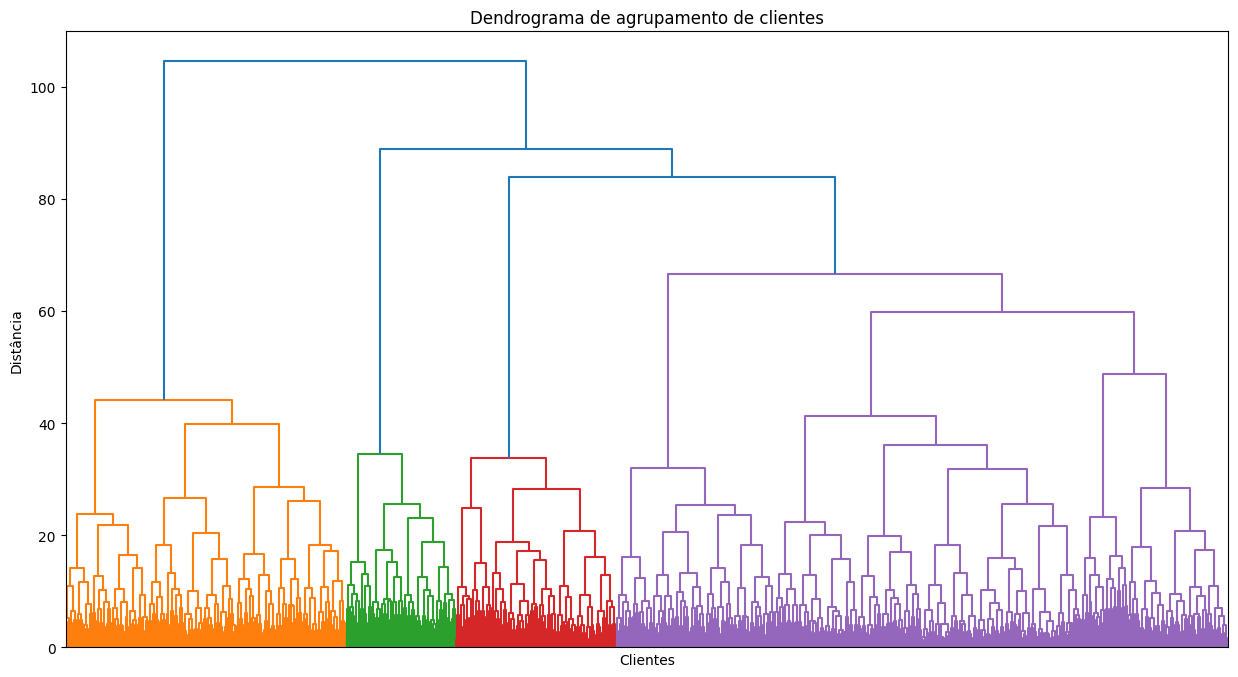

Valores médios por agrupamento:


cluster_km,0,1,2,3,4
gender,0.50,0.52,0.50,0.49,0.56
Near_Location,0.96,0.86,0.00,1.00,0.98
Partner,0.78,0.47,0.46,0.35,0.36
Promo_friends,0.57,0.31,0.08,0.24,0.23
Phone,1.00,0.00,1.00,1.00,1.00
Contract_period,10.89,4.79,2.35,1.95,2.67
Group_visits,0.54,0.43,0.22,0.34,0.47
Age,29.98,29.30,28.48,28.17,30.13
Avg_additional_charges_total,160.76,143.96,135.46,131.62,161.66
Month_to_end_contract,9.95,4.48,2.20,1.86,2.46


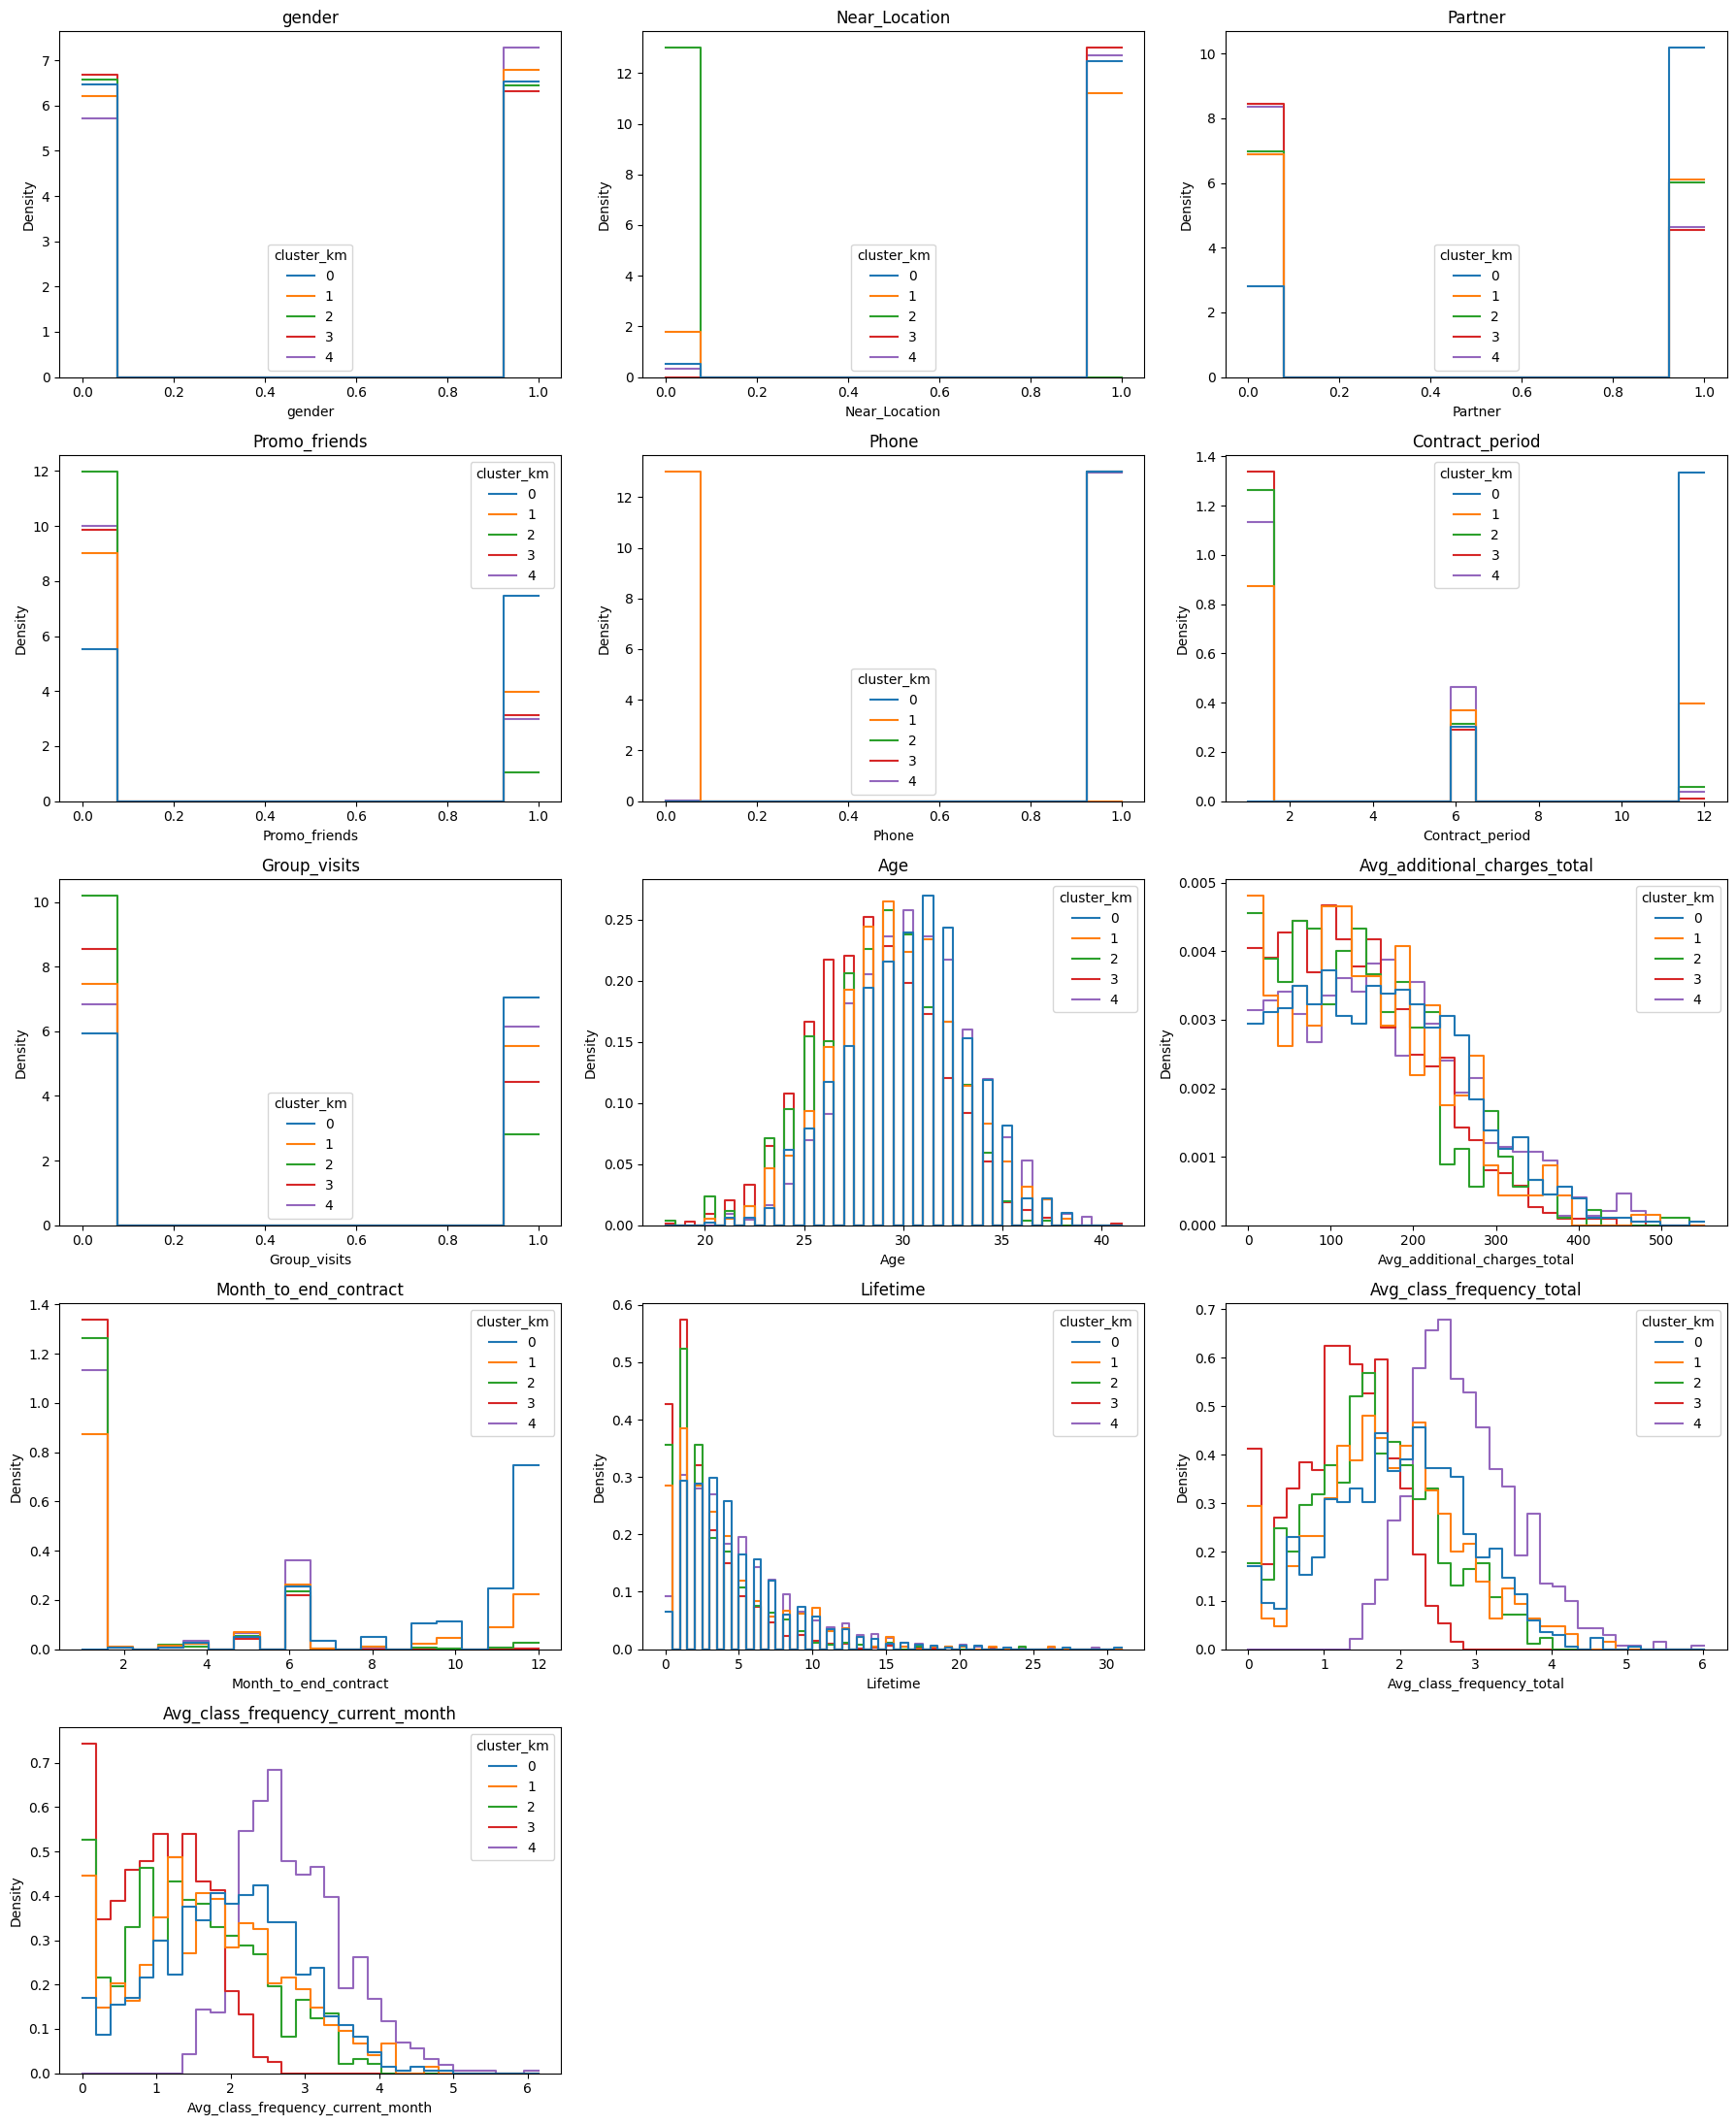

Taxa de rotatividade por agrupamento:


,clientes,taxa_rotatividade
cluster_km,,
3,1262,0.51
2,505,0.44
1,385,0.27
4,838,0.07
0,1010,0.03


In [5]:
# separar a coluna Churn e padronizar as demais características
gym_km = gym.copy()
X_cl = gym_km.drop('Churn', axis=1)

sc = StandardScaler()
X_cl_st = sc.fit_transform(X_cl)

# matriz de distâncias e dendrograma (pode demorar um pouco)
linked = linkage(X_cl_st, method='ward')

plt.figure(figsize=(15, 8))
dendrogram(linked, orientation='top', no_labels=True)
plt.title('Dendrograma de agrupamento de clientes')
plt.xlabel('Clientes')
plt.ylabel('Distância')
plt.show()

# modelo K-means com 5 agrupamentos
km = KMeans(n_clusters=5, random_state=0)
labels = km.fit_predict(X_cl_st)

# guardar o agrupamento de cada cliente
gym_km['cluster_km'] = labels

# valores médios das características por agrupamento
print('Valores médios por agrupamento:')
display(gym_km.groupby('cluster_km').mean().T.round(2))

# distribuições das características por agrupamento
features = [col for col in X_cl.columns]

fig, axes = plt.subplots(5, 3, figsize=(18, 22))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sns.histplot(data=gym_km, x=col, hue='cluster_km', stat='density', common_norm=False,
                 element='step', fill=False, palette='tab10', ax=ax)
    ax.set_title(col)

for ax in axes[len(features):]:
    ax.remove()

plt.tight_layout()
plt.show()

# tamanho e taxa de rotatividade de cada agrupamento
churn_by_cluster = gym_km.groupby('cluster_km').agg(clientes=('Churn', 'count'),
                                                    taxa_rotatividade=('Churn', 'mean'))
print('Taxa de rotatividade por agrupamento:')
display(churn_by_cluster.round(2).sort_values('taxa_rotatividade', ascending=False))

### Avaliação do Passo 4

**Dendrograma:** o gráfico mostra 4 ramos principais bem definidos (laranja, verde, vermelho e roxo). O ramo roxo é o maior e ainda se divide em subgrupos antes de ser cortado, então o dendrograma é compatível com a escolha de **5 agrupamentos**, que é o número indicado pelo enunciado.

**Agrupamentos do K-means (n = 5)**

| Agrupamento | Clientes | Taxa de rotatividade |
|---|---|---|
| 3 | 1.262 | 51% |
| 2 | 505 | 44% |
| 1 | 385 | 27% |
| 4 | 838 | 7% |
| 0 | 1.010 | 3% |

Os agrupamentos diferem bastante na rotatividade: dois são **propensos a sair** (3 e 2), um é intermediário (1) e dois são **leais** (4 e 0).

**Perfil de cada agrupamento (valores médios)**

- **Agrupamento 0, o mais leal (3% de rotatividade):** contratos longos (10,9 meses em média), 78% são de empresas parceiras, 57% vieram por indicação de amigos, 54% fazem aulas em grupo, moram perto e gastam mais em serviços adicionais (160,76). Frequência de cerca de 2 visitas por semana.
- **Agrupamento 4, o mais frequente (7%):** é o que mais frequenta a academia (2,85 visitas por semana, tanto no total quanto no mês atual), tem a maior permanência (4,9 meses) e o maior gasto adicional (161,66). Chama atenção que o contrato é curto (2,7 meses em média), mas mesmo assim quase não sai.
- **Agrupamento 1, sem telefone (27%):** é o único em que **ninguém forneceu o número de telefone** (`Phone` = 0). Os demais valores ficam em torno da média geral (contrato de 4,8 meses, frequência de 1,7 por semana).
- **Agrupamento 2, mora longe (44%):** é o único em que **ninguém mora ou trabalha perto da academia** (`Near_Location` = 0). Quase não vêm por indicação de amigos (8%), têm contratos curtos (2,35 meses) e frequência baixa no mês (1,48).
- **Agrupamento 3, o maior e com a maior rotatividade (51%):** moram perto, mas têm contratos muito curtos (1,95 mês), são os mais jovens (28,2 anos), os que menos frequentam (1,01 visita por semana no mês atual contra 1,25 no total) e os que menos gastam (131,62).

**Distribuições por agrupamento:** os gráficos confirmam o que aparece nas médias. `Phone` separa apenas o agrupamento 1 e `Near_Location` separa apenas o 2. O `Contract_period` do agrupamento 0 se concentra em 12 meses, e o dos demais se concentra em 1 mês. A frequência de visitas do agrupamento 4 está deslocada para a direita (mais visitas), e a do agrupamento 3 está deslocada para a esquerda, com muitos clientes perto de 0 visitas no mês atual. O `gender` é praticamente igual em todos os agrupamentos (0,49 a 0,56), então não ajuda a separá-los.

**Principais conclusões:** a rotatividade se associa principalmente ao **tamanho do contrato** e à **frequência nas aulas**. O contrato curto sozinho não decide, porque o agrupamento 4 tem contrato curto e não sai, o que sugere que **frequentar a academia é um forte fator de retenção**. A **distância da academia** e a **falta de telefone cadastrado** também marcam grupos com mais risco.

## Passo 5. Conclusões e recomendações

### Principais conclusões

1. **A rotatividade acontece no início do relacionamento.** Quem saiu tem em média apenas 1 mês de casa (`Lifetime` = 0,99 contra 4,71 de quem ficou) e contratos de cerca de 1,7 mês (contra 5,75).
2. **A frequência é o sinal mais forte de que o cliente vai sair.** Quem saiu frequenta cerca de 1,04 vez por semana no mês atual, contra 2,03 de quem ficou, e a frequência do mês atual caiu em relação à média total (1,47). As características mais correlacionadas com a rotatividade foram `Lifetime` (-0,44), frequência no mês atual (-0,41), idade (-0,40), `Contract_period` (-0,39) e `Month_to_end_contract` (-0,38).
3. **O vínculo com a academia protege o cliente.** Quem ficou participa mais de aulas em grupo (46% contra 27%), é mais de empresas parceiras (53% contra 36%), veio mais por indicação de amigos (35% contra 18%), gasta mais em serviços adicionais (158,45 contra 115,08) e é um pouco mais velho (30 contra 27 anos).
4. **Os modelos conseguem prever bem quem vai sair.** A regressão logística teve acurácia de 0,92, precisão de 0,85 e sensibilidade de 0,83, o que permite criar uma lista de clientes em risco para agir com antecedência.
5. **Os clientes se dividem em 5 perfis com riscos muito diferentes.** O agrupamento 3 (1.262 clientes) tem 51% de rotatividade, o agrupamento 2 (505 clientes) tem 44% e o agrupamento 1 (385 clientes) tem 27%. Já os agrupamentos 4 (838 clientes) e 0 (1.010 clientes) têm só 7% e 3%.
6. **O gênero e o telefone cadastrado não parecem influenciar.** As médias e as distribuições são praticamente iguais entre quem saiu e quem ficou.

### Grupos-alvo

- **Agrupamento 3 (prioridade máxima):** moram perto, mas têm contratos de cerca de 2 meses, são os mais jovens (28 anos), frequentam pouco (1,01 por semana no mês atual) e gastam menos.
- **Agrupamento 2:** moram ou trabalham longe da academia, têm contratos curtos, poucas indicações de amigos e frequência baixa.
- **Agrupamento 1 (risco intermediário):** não deixaram o telefone e saem em 27% dos casos.

### Recomendações

1. **Cuidar dos primeiros 2 meses.** Criar um programa de boas-vindas: uma aula experimental com instrutor, um plano de treino inicial e um contato da equipe por volta da segunda semana para quem ainda não voltou.
2. **Usar a frequência como alerta.** Monitorar o número de visitas por semana e, quando o cliente cair abaixo de cerca de 1 visita, enviar uma mensagem personalizada ou uma oferta de aula em grupo. Combinar isso com a previsão do modelo para priorizar os clientes em risco.
3. **Converter contratos curtos em longos.** Para clientes de 1 mês, perto do fim do contrato, oferecer desconto na renovação por 6 ou 12 meses. O agrupamento 4 mostra que mesmo com contrato curto, quem frequenta muito permanece, então vale oferecer o contrato longo a esse grupo para garantir a fidelidade.
4. **Estimular o vínculo social.** Promover as aulas em grupo, reforçar o programa "traga um amigo" e expandir as parcerias com empresas, já que esses clientes ficam mais.
5. **Adaptar a oferta para quem mora longe (agrupamento 2).** Oferecer planos flexíveis, como menos visitas por mês ou aulas em horários de pico no trabalho, e promoções para quem vem de empresas parceiras próximas ao local de trabalho.
6. **Contatar o agrupamento 1 por outros canais.** Como não há telefone cadastrado, usar e-mail ou o aplicativo para as campanhas de retenção.
7. **Manter os clientes leais engajados (agrupamentos 0 e 4).** Convidá-los a indicar amigos com benefícios e oferecer serviços adicionais, já que são os que mais gastam.

### Outros padrões observados

- A idade tem efeito moderado: os clientes mais jovens saem mais.
- As variáveis `Contract_period` e `Month_to_end_contract` (0,97) e as frequências total e do mês atual (0,95) são quase redundantes, o que deve ser considerado em modelos lineares.